# The signal and the noise region

**Question:** How does giving up control of the light outside the signal region buy accuracy inside it, and how much of the focal plane has to be given up?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (the disc, the error and plain Gerchberg-Saxton)
- **Reading time:** about 50 minutes; the notebook runs in about 2 minutes

## Objectives

Plain Gerchberg-Saxton forces every bin of the focal plane to a value: the target inside the shape and zero everywhere else. A phase-only hologram cannot do that, and the disc of the previous notebook ends with an error of 0.4411. Mixed-region amplitude freedom (MRAF) lifts the constraint outside a chosen region and lets the light go there. This notebook builds that region by hand, as a square window of growing size around the disc, and runs the product's MRAF on each window with the mixing parameter fixed at 0.3. You will see where the power goes, how the error depends on how much of the grid is left free, why a window that covers the whole grid gives exactly plain Gerchberg-Saxton, what the light in the free region looks like, and whether the dark margin around the shape matters. At the end you will be able to choose a signal region for a shaped target and say what it costs.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with their exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in `data-pipeline/pipeline/` and the notebook imports them by their path. The next cell imports the tools, prints their versions and puts the pipeline on the path.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import copy
import importlib.metadata as md
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.baseline import m04_gs, m08_mraf

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2


## Data

- Owner: this repository, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Licence class: synthetic case written by the product, no third-party dataset, covered by the repository licence.
- File read: `data/examples/cases.json`, case C04: a disc of 15 um radius on a 256 by 256 pixel SLM, padded to a focal grid of 512 by 512 bins, 30 iterations and a signal-region margin of 3 bins. The device of the case (8 bits and crosstalk) is not used here.

In [2]:
# case C04 gives the SLM, the beam and the disc; copies of its record change only the margin of the signal region
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C04_disc_crosstalk"]
setup = setup_of(rec)
disc = target_of(rec)
seed, budget = rec["seed"], Budget(rec["budget"]["iterations"])
n, c = setup.n_fft, setup.n_fft // 2
shape = disc.amplitude > 0
print(f"focal grid {n} x {n}, shape {int(shape.sum())} bins")
print(f"case margin {rec['target']['signal_margin_bins']} bins, iterations {budget.iterations}")

focal grid 512 x 512, shape 2861 bins
case margin 3 bins, iterations 30


## Method

**The rule.** MRAF (Pasienski and DeMarco 2008, Eq. 1, https://doi.org/10.1364/OE.16.002176) splits the focal grid into a signal region SR and a noise region NR and replaces the field after each pass by $G = \{ m\,T|_{SR} + (1-m)\,|E|\,|_{NR} \}\,e^{i \arg E}$, then returns to the SLM with $\phi \leftarrow \arg \mathcal{F}^{-1}\{G\}$. Inside SR the amplitude is forced to $mT$; in NR it keeps $1-m$ of whatever the hologram made, so power that the shape does not need drains into NR. With $m = 1$ the noise region is multiplied by zero, which is plain Gerchberg-Saxton, and the product's M04 on a shaped target is exactly that. The notebook fixes $m = 0.3$, the product's default, and varies the region; the next notebook varies $m$.

**The region.** The case's signal region is the disc dilated by 3 bins, so NR is almost the whole grid. To see the effect of NR's size, the notebook builds its own regions: a square window of half-width $h$ bins around the axis, joined with the shape, and an NR that is everything outside the window. The target is the same disc. The error is the one of notebook 01, $\eta = \sqrt{\langle ((sI - T^2)/T^2)^2 \rangle}$ on the shape eroded by one resolution cell (Eq. 2 of the same paper), and the power is split into three shares: in the shape, in the rest of SR, and in NR.

The first step builds the windows. The cell defines a function that returns the shaped target for a half-width and prints, for half-widths of 48, 96, 144, 192, 240 and 256 bins, how many bins are signal and how many are noise. A half-width of 256 covers the whole grid of 512.

In [3]:
# a hand-built signal region: a square window of half-width h bins around the axis, plus the shape itself
def windowed(half_width):
    mask = np.zeros((n, n), dtype=bool)
    mask[c - half_width:c + half_width, c - half_width:c + half_width] = True
    return Target.from_field(disc.amplitude, mask | shape)


windows = (48, 96, 144, 192, 240, 256)
for h in windows:
    free = ~windowed(h).mask
    print(f"h = {h:3d}: signal region {int(windowed(h).mask.sum()):6d},", end=" ")
    print(f"noise region {int(free.sum()):6d} bins = {100 * free.mean():5.1f} %")

h =  48: signal region   9216, noise region 252928 bins =  96.5 %
h =  96: signal region  36864, noise region 225280 bins =  85.9 %
h = 144: signal region  82944, noise region 179200 bins =  68.4 %
h = 192: signal region 147456, noise region 114688 bins =  43.8 %
h = 240: signal region 230400, noise region  31744 bins =  12.1 %
h = 256: signal region 262144, noise region      0 bins =   0.0 %


The noise region goes from 96.5 percent of the grid at half-width 48 to 12.1 percent at 240 and none at 256, where every bin belongs to the signal region. The second step fixes the reference. The cell runs M04 on the disc with the case's own signal region and splits its power into three shares, in the shape, in the margin of the signal region and outside it, next to the error.

In [4]:
# M04 on the disc: the noise region is forced to zero, the reference of the whole notebook
def power_split(phi, target):
    power = np.abs(forward.fft_focal_field(phi, setup)) ** 2 / setup.n_pix**2
    return power[shape].sum(), power[target.mask & ~shape].sum(), power[~target.mask].sum()


plain = m04_gs.run(setup, disc, budget=budget, rng=Rng(seed))
inside, margin, outside = power_split(plain.phi, disc)
print(f"M04: error {plain.history[-1]['error']:.4f}")
print(f"power in the shape {inside:.4f}, in the margin of the signal region {margin:.4f}, outside {outside:.4f}")

M04: error 0.4411
power in the shape 0.9531, in the margin of the signal region 0.0090, outside 0.0379


M04 puts 0.9531 of the input power in the shape, 0.0090 in the margin and 0.0379 outside it, with the error of 0.4411 already seen. It has no noise region, so the light that is not in the shape has nowhere to go but the margin and the rest of the grid, which hold 0.0469 between them. The third step is the experiment. For each half-width the cell runs the product's MRAF on that region and prints the error and the three shares of power.

In [5]:
# MRAF (M08, mixing 0.3) on each hand-built region: the error and where the power goes
runs = {}
for h in windows:
    target = windowed(h)
    runs[h] = m08_mraf.run(setup, target, budget=budget, rng=Rng(seed), mixing=0.3)
    inside, margin, outside = power_split(runs[h].phi, target)
    print(f"h = {h:3d}: error {runs[h].history[-1]['error']:.4f}, power in the shape {inside:.4f}, "
          f"margin {margin:.4f}, noise region {outside:.4f}")

h =  48: error 0.0482, power in the shape 0.1787, margin 0.0010, noise region 0.8203
h =  96: error 0.0405, power in the shape 0.1800, margin 0.0015, noise region 0.8185
h = 144: error 0.0687, power in the shape 0.1791, margin 0.0031, noise region 0.8178
h = 192: error 0.2029, power in the shape 0.1794, margin 0.0083, noise region 0.8122
h = 240: error 0.2320, power in the shape 0.1874, margin 0.0299, noise region 0.7827
h = 256: error 0.4411, power in the shape 0.9531, margin 0.0469, noise region 0.0000


The errors are 0.0482, 0.0405, 0.0687, 0.2029, 0.2320 and 0.4411 for half-widths 48, 96, 144, 192, 240 and 256. With a free region of 85.9 percent of the grid the error falls to 0.0405, eleven times lower than the plain loop, and at 12.1 percent it is 0.2320, half of it. The power in the shape is about 0.18 for every window, from 0.1787 to 0.1874, and the noise region holds between 0.7827 and 0.8203 of the input power: the window decides the accuracy and not the share of power in the shape, which suggests that, at this value of the mixing, it is the mixing that sets that share. The last row is the whole grid, and it has the numbers of M04 to the last digit: error 0.4411 and 0.9531 of the power in the shape. The next cell tests that identity directly, by comparing the two phases.

In [6]:
# with an empty noise region MRAF has nothing to move the power into: compare its phase with the one of M04
gap = np.angle(np.exp(1j * (runs[256].phi - plain.phi)))
print(f"largest phase difference between M04 and MRAF with h = 256 (rad): {np.abs(gap).max():.2e}")
print(f"errors: M04 {plain.history[-1]['error']:.4f}, MRAF h = 256 {runs[256].history[-1]['error']:.4f}")

largest phase difference between M04 and MRAF with h = 256 (rad): 4.84e-10
errors: M04 0.4411, MRAF h = 256 0.4411


The largest difference between the phase of M04 and that of MRAF with the window at half-width 256 is 4.84e-10 rad, rounding error, and both errors are 0.4411. With no noise region, mixing $m$ scales the whole target by a constant, and a constant does not change the phase that a Gerchberg-Saxton step keeps. So plain Gerchberg-Saxton is the end of this family and MRAF does not need a second algorithm: it needs a region. The figure draws the whole experiment. The left panel stacks, for each configuration, the power in the shape (blue), in the margin of the signal region (orange) and in the noise region (green); the right panel plots the error of MRAF on a logarithmic axis against the share of the grid that is noise, with the plain loop as a dashed line and each point labelled with its half-width.

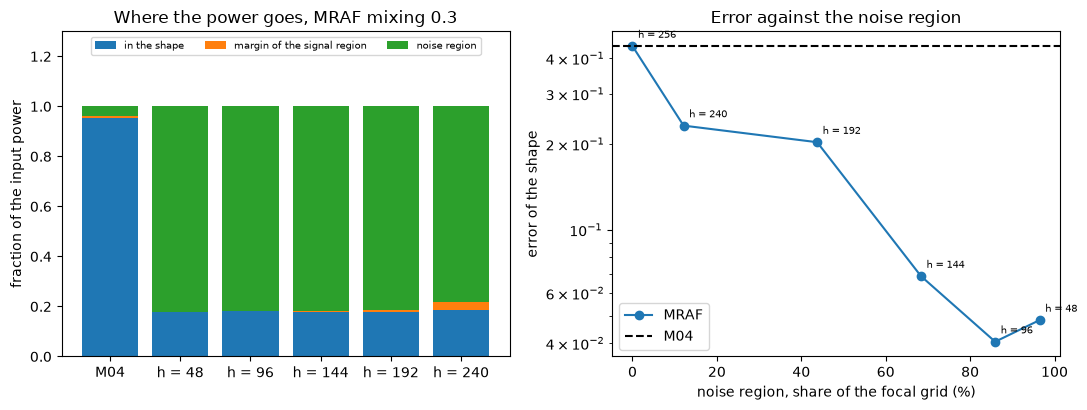

In [7]:
# left: where the power goes; right: the error against the share of the grid left to noise
labels = ["M04"] + [f"h = {h}" for h in windows[:-1]]
splits = [power_split(plain.phi, disc)] + [power_split(runs[h].phi, windowed(h)) for h in windows[:-1]]
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2))
bottom = np.zeros(len(labels))
for k, name in enumerate(("in the shape", "margin of the signal region", "noise region")):
    part = np.array([s[k] for s in splits])
    left.bar(labels, part, bottom=bottom, label=name)
    bottom += part
left.set_ylabel("fraction of the input power")
left.set_title("Where the power goes, MRAF mixing 0.3")
left.set_ylim(0, 1.3)
left.legend(loc="upper center", ncol=3, fontsize=7.5)
share = [100 * (~windowed(h).mask).mean() for h in windows]
right.semilogy(share, [runs[h].history[-1]["error"] for h in windows], "o-", label="MRAF")
for h, x_share in zip(windows, share):
    point = (x_share, runs[h].history[-1]["error"])
    right.annotate(f"h = {h}", point, textcoords="offset points", xytext=(4, 6), fontsize=7.5)
right.axhline(plain.history[-1]["error"], color="k", ls="--", label="M04")
right.set_xlabel("noise region, share of the focal grid (%)")
right.set_ylabel("error of the shape")
right.set_title("Error against the noise region")
right.legend()
fig.tight_layout()
plt.show()

On the left, M04 keeps 0.9531 of the power in the shape, and every MRAF bar has the same blue base of about 0.18 and a green top that holds the rest, so the whole difference between accurate and inaccurate is in where the other four fifths of the light is allowed to be. On the right, the error does not fall in proportion to the free area: it drops from 0.4411 to 0.2320 and 0.2029 when 12.1 and 43.8 percent of the grid are free, then to 0.0687, 0.0405 and 0.0482 at 68.4, 85.9 and 96.5 percent. It bottoms out around the 86 percent point, and the small rise at 96.5 percent is of the size of the variation that the last step finds between margins: each point is one run, so the order of the two smallest windows is not established. The figure shows power and error and not what the free light looks like, which is the next figure.

The cell draws the focal power on a logarithmic scale for the smallest window, half-width 48, and for the one with the thinnest noise region, half-width 240, with the border of the window as a cyan line.

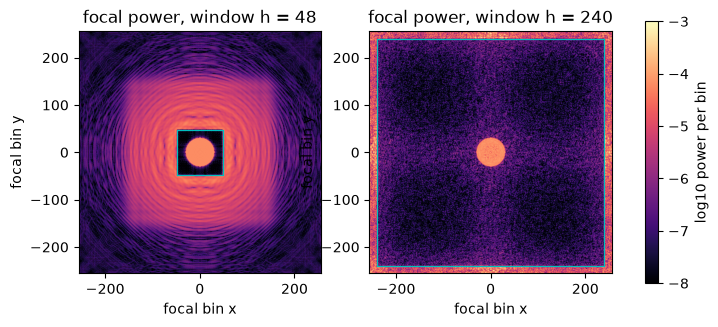

In [8]:
# the focal power on a log scale for the smallest and the largest window that is not the whole grid
fig, axes = plt.subplots(1, 2, figsize=(8.6, 4.0))
for ax, h in zip(axes, (48, 240)):
    power = np.abs(forward.fft_focal_field(runs[h].phi, setup)) ** 2 / setup.n_pix**2
    image = ax.imshow(np.log10(power + 1e-9), origin="lower", vmin=-8, vmax=-3, cmap="magma", extent=(-c, c, -c, c))
    ax.plot([-h, h, h, -h, -h], [-h, -h, h, h, -h], color="c", lw=0.9)
    ax.set_title(f"focal power, window h = {h}")
    ax.set_xlabel("focal bin x")
    ax.set_ylabel("focal bin y")
fig.colorbar(image, ax=axes, label="log10 power per bin", shrink=0.85)
plt.show()

With half-width 48, left, the disc is a bright, flat spot in a dark square that is the signal region, and the noise region carries a smooth halo with concentric rings several times larger than the window: the light that the disc does not want spreads out over about 150 bins in all directions and is faint everywhere, more than an order of magnitude below the disc per bin. With half-width 240, right, the window is almost the whole grid, the interior is dark speckle, and the light is stacked against the border of the window in the thin frame that is left: there it is brighter than anywhere outside the disc, because it has nowhere else to go. This is why a thin noise region gives a worse error than a wide one: a thin free region may not absorb the light without raising the speckle inside the signal region, a reading that this notebook did not test. The figure does not show whether the halo matters for an experiment. A potential with 0.8 of the light in a faint halo may heat the atoms or act on a gas that is not meant to feel it, which the error cannot tell.

The last step asks about the dark margin that the case adds around the shape. The cell reruns MRAF on the disc with margins of 0 and 12 bins, by changing the margin in a copy of the case's record, and next to them the case's own margin of 3.

In [9]:
# the dark margin: the case's margin of 3 bins against none and 12 bins, through the record of the target
for bins in (0, 12):
    variant = copy.deepcopy(rec)
    variant["target"]["signal_margin_bins"] = bins
    target = target_of(variant)
    res = m08_mraf.run(setup, target, budget=budget, rng=Rng(seed), mixing=0.3)
    inside = power_split(res.phi, target)[0]
    print(f"margin {bins:2d} bins: error {res.history[-1]['error']:.4f}, power in the shape {inside:.4f}")
res = m08_mraf.run(setup, disc, budget=budget, rng=Rng(seed), mixing=0.3)
inside = power_split(res.phi, disc)[0]
print(f"margin  3 bins: error {res.history[-1]['error']:.4f}, power in the shape {inside:.4f}")

margin  0 bins: error 0.0460, power in the shape 0.1696
margin 12 bins: error 0.0585, power in the shape 0.1641
margin  3 bins: error 0.0517, power in the shape 0.1712


A margin of 0 bins gives an error of 0.0460 with 0.1696 of the power in the shape, 3 bins give 0.0517 and 0.1712, and 12 bins give 0.0585 and 0.1641. The margin moves the error by about 0.01 over a range of 12 bins, which is the order of the differences between the windows with the thinnest noise region, so these numbers do not tell the three margins apart. They say that the margin is a minor choice here compared with the size of the free region, whose effect is a factor of ten. The margin matters for another reason that the numbers do not show: a dark margin forces the light off the neighbours of the shape, which an experiment with atoms near the disc may need.

## Results

**Answer:** Giving up the control of the light outside the signal region lets the hologram stop compromising inside it: with MRAF at mixing 0.3, a free region of 85.9 percent of the focal grid brings the error of the disc from 0.4411 to 0.0405, a factor of eleven, and even 12.1 percent of the grid brings it to 0.2320. Accuracy needs a free region and then saturates: from 68.4 to 96.5 percent of the grid the error stays between 0.0405 and 0.0687, while below 44 percent it is at least 0.2029. The price is power: the shape keeps about 0.18 of the input power for every window short of the whole grid, from 0.1787 to 0.1874, against 0.9531 for the plain loop, and the noise region holds between 0.7827 and 0.8203 of it. With no free region the answer is plain Gerchberg-Saxton to rounding, 4.84e-10 rad in the phase. The dark margin of 0, 3 or 12 bins changes the error between 0.0460 and 0.0585 and does not decide the matter. The notebook ran one case, one mixing value and one run per window, so differences of about 0.01 between neighbouring windows are not resolved, and it did not test what the free light does to an experiment.

## Summary

Accuracy on a shaped target comes from the region where the algorithm is not asked to produce anything. A window that leaves 68 to 96 percent of the grid free brings the disc to an error of 0.04 to 0.07, a window that leaves none is plain Gerchberg-Saxton, and in between the error falls with the free area. The cost is that four fifths of the light goes to a halo. The next notebook takes the mixing parameter, which sets how much light the shape keeps, and compares the product's MRAF with slmsuite's on a disc and a ring.

## References

- Pasienski and DeMarco, "A high-accuracy algorithm for designing arbitrary holographic atom traps", Optics Express 16, 2176 (2008), https://doi.org/10.1364/OE.16.002176.
- Di Leonardo, Ianni and Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.